# 反射式多普勒效应综合实验

**实验项目**：反射式多普勒效应综合实验  
**实验大纲依据**：中国海洋大学物理实验教学中心《反射式多普勒效应综合实验》讲义  

---

## 一、实验目的与原理

### 1. 实验目的
1. 通过该实验进一步了解多普勒效应原理及其在工程、医疗、科研等领域的应用；
2. 熟悉 DPL-F 反射式多普勒超声综合实验仪的使用；
3. 熟练掌握数字示波器的使用；
4. 测量不同转速下小车的运动速度与频差，计算声速及其不确定度，并与理论声速对比求相对误差；
5. 利用求得的声速进行超声测速，验证多普勒测速原理。

---

### 2. 实验原理与计算公式

#### (1) 反射式多普勒频差与声速计算公式
超声发射探头与接收探头固定于导轨右端。小车在导轨上以速度 $v$ 运动，超声波经小车反射后被接收器接收。
根据讲义原理公式（4）与公式（5）：
* **小车靠近超声头时**：
  $$v = \frac{\Delta f}{2f_0 + \Delta f} u \implies u = \frac{2f_0 + \Delta f}{\Delta f} v$$
* **小车远离超声头时**：
  $$v = \frac{\Delta f}{2f_0 - \Delta f} u \implies u = \frac{2f_0 - \Delta f}{\Delta f} v$$
其中 $f_0 = 40.0\,\mathrm{kHz}$ 为发射频率，$\Delta f$ 为接收信号与发射信号的差频。

#### (2) 理论声速公式 (讲义公式 6)
环境摄氏温度为 $t$ 时，干燥空气中的理论声速为：
$$u_{\text{theory}} = 331.45 \sqrt{1 + \frac{t}{273.15}} \quad (\mathrm{m/s})$$

#### (3) 声速不确定度评定与相对误差
多次测量声速的算术平均值 $\bar{u}$、Bessel 样本实验标准差 $s$ 与 A 类标准不确定度 $u_A$：
$$\bar{u} = \frac{1}{n} \sum_{i=1}^n u_i, \quad s = \sqrt{\frac{1}{n-1} \sum_{i=1}^n (u_i - \bar{u})^2}, \quad u = u_A = \frac{s}{\sqrt{n}}$$
相对标准不确定度与相对理论误差分别为：
$$u_r = \frac{u}{\bar{u}} \times 100\%, \quad E_r = \frac{|\bar{u} - u_{\text{theory}}|}{u_{\text{theory}}} \times 100\%$$

#### (4) 利用声速进行超声测速公式
利用实验一求得的平均声速 $\bar{u}$ 反算小车速度：
* 靠近时：$v_{\text{calc}} = \frac{\Delta f}{2f_0 + \Delta f} \bar{u}$
* 远离时：$v_{\text{calc}} = \frac{\Delta f}{2f_0 - \Delta f} \bar{u}$


In [43]:
import math
from decimal import Decimal
import matplotlib.pyplot as plt

# 导入项目核心标准计算工具包 (严格符合 JJF 1059 与大物实验教学规范)
from python.utils import scientific_round, linear_regression

# 设置绘图字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120


### 1. 实验环境参数与原始测量数据记录

根据实验报告记录：
* **室内温度**：$t_{\text{start}} = 20.8\,^\circ\mathrm{C}$ 渐上涨至 $t_{\text{end}} = 21.2\,^\circ\mathrm{C}$，全程平均温度 $t = 21.0\,^\circ\mathrm{C}$；
* **超声波初始频率**：$f_0 = 40.0\,\mathrm{kHz} = 40000.0\,\mathrm{Hz}$；
* **挡光板长度**：$d = 5.00\,\mathrm{cm} = 0.0500\,\mathrm{m}$；
* **实验一**：7 个电机转速挡位（20% ~ 80%），每个挡位 6 次往返测量，共 42 组小车速度、频差（单片机）与示波器频差数据；
* **实验二**：速度 1、速度 2、速度 3，各 6 次测量，共 18 组超声测速频差数据。


In [44]:
# ==================== 1. 实验参数配置 ====================
t_start = Decimal("20.8")
t_end = Decimal("21.2")
t_celsius = (t_start + t_end) / Decimal("2")  # 21.0 ℃
f0 = Decimal("40000.0")                      # 40 kHz
d_gate = Decimal("0.0500")                   # 5.00 cm

# ==================== 2. 实验一原始数据录入 (42 组) ====================
exp1_raw_dict = {
    "20%": (Decimal("0.082"), 
            [Decimal(x) for x in ["18.98", "19.15", "19.11", "19.21", "19.13", "18.97"]],
            [Decimal(x) for x in ["18.658", "18.837", "19.287", "18.806", "18.907", "18.936"]]),
    "30%": (Decimal("0.123"),
            [Decimal(x) for x in ["28.52", "28.43", "28.84", "28.45", "28.45", "28.27"]],
            [Decimal(x) for x in ["28.156", "28.288", "28.453", "28.686", "28.994", "28.786"]]),
    "40%": (Decimal("0.165"),
            [Decimal(x) for x in ["38.34", "38.27", "37.93", "37.92", "38.11", "38.17"]],
            [Decimal(x) for x in ["37.394", "37.801", "37.309", "38.700", "38.633", "38.873"]]),
    "50%": (Decimal("0.205"),
            [Decimal(x) for x in ["47.19", "48.15", "47.60", "47.51", "47.46", "47.52"]],
            [Decimal(x) for x in ["47.849", "48.642", "48.330", "49.306", "47.882", "48.224"]]),
    "60%": (Decimal("0.247"),
            [Decimal(x) for x in ["57.10", "56.90", "56.90", "56.75", "57.09", "57.04"]],
            [Decimal(x) for x in ["57.994", "55.973", "55.022", "57.182", "58.812", "55.565"]]),
    "70%": (Decimal("0.289"),
            [Decimal(x) for x in ["67.33", "66.40", "66.96", "66.66", "67.05", "66.72"]],
            [Decimal(x) for x in ["65.111", "65.796", "65.880", "66.650", "68.370", "64.979"]]),
    "80%": (Decimal("0.330"),
            [Decimal(x) for x in ["76.20", "76.12", "76.30", "76.27", "76.28", "75.97"]],
            [Decimal(x) for x in ["77.524", "76.782", "73.573", "76.546", "74.587", "74.806"]])
}

# ==================== 3. 实验二原始数据录入 (18 组) ====================
exp2_raw_dict = {
    "速度 1": (Decimal("0.289"),
              [Decimal(x) for x in ["66.69", "66.92", "66.65", "66.87", "66.95", "67.47"]],
              [Decimal(x) for x in ["66.327", "69.141", "64.480", "69.198", "69.735", "68.224"]]),
    "速度 2": (Decimal("0.247"),
              [Decimal(x) for x in ["57.04", "57.03", "56.79", "57.30", "56.72", "57.18"]],
              [Decimal(x) for x in ["59.380", "56.576", "55.702", "58.042", "57.135", "58.392"]]),
    "速度 3": (Decimal("0.205"),
              [Decimal(x) for x in ["47.57", "47.45", "47.30", "47.51", "47.58", "47.43"]],
              [Decimal(x) for x in ["48.420", "46.401", "46.841", "47.865", "46.846", "46.054"]])
}

print(f"室内温度: {t_start} ℃ ~ {t_end} ℃ (平均 {t_celsius} ℃)")
print(f"发射中心频率: f0 = {f0} Hz")
print(f"实验一数据点: {sum(len(v[1]) for v in exp1_raw_dict.values())} 组")
print(f"实验二数据点: {sum(len(v[1]) for v in exp2_raw_dict.values())} 组")


室内温度: 20.8 ℃ ~ 21.2 ℃ (平均 21.0 ℃)
发射中心频率: f0 = 40000.0 Hz
实验一数据点: 42 组
实验二数据点: 18 组


### 2. 实验一数据处理：逐次声速计算、平均声速与不确定度评定

1. **求出各次测量声速**：
   * 靠近探头时：$u = \frac{2f_0 + \Delta f}{\Delta f} v$
   * 远离探头时：$u = \frac{2f_0 - \Delta f}{\Delta f} v$
2. **计算声速平均值与实验标准差**：
   $$\bar{u} = \frac{1}{n} \sum_{i=1}^n u_i, \quad s = \sqrt{\frac{1}{n-1} \sum_{i=1}^n (u_i - \bar{u})^2}$$
3. **计算 A 类标准不确定度**：
   $$u_A = \frac{s}{\sqrt{n}}$$
4. **计算理论声速与相对误差**：
   $$u_{\text{theory}} = 331.45 \sqrt{1 + \frac{t}{273.15}}, \quad E_r = \frac{|\bar{u} - u_{\text{theory}}|}{u_{\text{theory}}} \times 100\%$$


In [45]:
# 1. 计算理论声速
u_theory = Decimal("331.45") * Decimal(str(math.sqrt(float(Decimal("1") + t_celsius / Decimal("273.15")))))

# 2. 计算 42 次声速
u_inst_list = []
u_osc_list = []
X_factor_list = []
v_list = []

print("=" * 105)
print("                   表 1: 反射式多普勒效应测定声速实验数据与计算结果表 (仪器直读 vs 示波器测量)")
print("=" * 105)
print(f"{'序号':^4} | {'转速':^5} | {'方向':^4} | {'速度 v(m/s)':^11} | {'Δf_inst(Hz)':^11} | {'u_inst(m/s)':^11} | {'Δf_osc(Hz)':^11} | {'u_osc(m/s)':^11} | {'理论偏差':^9} | {'相对误差':^8}")
print("-" * 105)

global_idx = 1
for gear, (v, df_inst_list, df_osc_list) in exp1_raw_dict.items():
    for i in range(len(df_inst_list)):
        df_inst = df_inst_list[i]
        df_osc = df_osc_list[i]
        
        # 奇数次 (i=0,2,4) 为靠近；偶数次 (i=1,3,5) 为远离
        if i % 2 == 0:
            direction = "靠近"
            u_inst = ((Decimal("2") * f0 + df_inst) / df_inst) * v
            u_osc = ((Decimal("2") * f0 + df_osc) / df_osc) * v
            X_factor = df_inst / (Decimal("2") * f0 + df_inst)
        else:
            direction = "远离"
            u_inst = ((Decimal("2") * f0 - df_inst) / df_inst) * v
            u_osc = ((Decimal("2") * f0 - df_osc) / df_osc) * v
            X_factor = df_inst / (Decimal("2") * f0 - df_inst)
            
        u_inst_list.append(u_inst)
        u_osc_list.append(u_osc)
        X_factor_list.append(X_factor)
        v_list.append(v)
        
        dev_inst = u_inst - u_theory
        rel_err = abs(dev_inst) / u_theory * Decimal("100")
        
        dev_str = f"+{float(dev_inst):.3f}" if dev_inst >= 0 else f"{float(dev_inst):.3f}"
        print(f"{global_idx:^4} | {gear:^5} | {direction:^4} | {float(v):^11.3f} | {float(df_inst):^11.2f} | {float(u_inst):^11.3f} | {float(df_osc):^11.3f} | {float(u_osc):^11.3f} | {dev_str:^9} | {float(rel_err):^7.2f}%")
        global_idx += 1

print("=" * 105)

# 3. 统计平均声速与不确定度评定
n_samples = len(u_inst_list)
mean_u_inst = sum(u_inst_list) / Decimal(str(n_samples))
mean_u_osc = sum(u_osc_list) / Decimal(str(n_samples))
s_u_inst = Decimal(str(math.sqrt(float(sum((x - mean_u_inst) ** 2 for x in u_inst_list) / Decimal(str(n_samples - 1))))))
u_a_inst = s_u_inst / Decimal(str(math.sqrt(n_samples)))
err_theory_percent = abs(mean_u_inst - u_theory) / u_theory * Decimal("100")

print(f"\n【实验一统计与不确定度分析结果】(样本容量 n = {n_samples}):")
print(f"  * 实验室理论声速       u_theory = {float(u_theory):.4f} m/s")
print(f"  * 仪器频差反解平均声速 u_avg    = {float(mean_u_inst):.4f} m/s")
print(f"  * 示波器频差反解平均值 u_osc    = {float(mean_u_osc):.4f} m/s")
print(f"  * Bessel 样本标准差    s        = {float(s_u_inst):.4f} m/s")
print(f"  * A 类标准不确定度     u_A      = {float(u_a_inst):.4f} m/s")
print(f"  * 与理论声速相对误差   E_r      = {float(err_theory_percent):.2f}%")


                   表 1: 反射式多普勒效应测定声速实验数据与计算结果表 (仪器直读 vs 示波器测量)
 序号  |  转速   |  方向  |  速度 v(m/s)  | Δf_inst(Hz) | u_inst(m/s) | Δf_osc(Hz)  | u_osc(m/s)  |   理论偏差    |   相对误差  
---------------------------------------------------------------------------------------------------------
 1   |  20%  |  靠近  |    0.082    |    18.98    |   345.709   |   18.658    |   351.674   |  +1.754   |  0.51  %
 2   |  20%  |  远离  |    0.082    |    19.15    |   342.477   |   18.837    |   348.169   |  -1.478   |  0.43  %
 3   |  20%  |  靠近  |    0.082    |    19.11    |   343.358   |   19.287    |   340.207   |  -0.597   |  0.17  %
 4   |  20%  |  远离  |    0.082    |    19.21    |   341.407   |   18.806    |   348.743   |  -2.548   |  0.74  %
 5   |  20%  |  靠近  |    0.082    |    19.13    |   342.999   |   18.907    |   347.043   |  -0.956   |  0.28  %
 6   |  20%  |  远离  |    0.082    |    18.97    |   345.727   |   18.936    |   346.348   |  +1.772   |  0.52  %
 7   |  30%  |  靠近  |    0.123    |    2

### 3. 实验一数据处理：最小二乘法线性拟合验证多普勒效应

将多普勒频差公式改写为速度 $v$ 与频移归一化因子 $X$ 的线性正比关系：
$$v = k \cdot X + b, \quad X = \frac{\Delta f}{2f_0 \pm \Delta f}$$
理论物理规律下，拟合直线斜率 $k$ 即为声速 $u_{\text{fit}}$，截距 $b = 0$。
通过线性拟合检验相关系数 $r$，并计算斜率的不确定度 $u(k)$，验证多普勒效应的线性规律。


In [46]:
# 最小二乘法一元线性拟合
k_fit, b_fit, r_fit, u_k_fit = linear_regression(X_factor_list, v_list)
rel_err_fit = abs(k_fit - u_theory) / u_theory * Decimal("100")

print("=" * 68)
print("              最小二乘法一元线性拟合验证多普勒效应 (n = 42)")
print("=" * 68)
print(f"拟合方程形式            : v = k · X + b")
print(f"自变量 X 定义           : Δf / (2f0 ± Δf)")
print(f"拟合斜率 k (拟合声速)   : {float(k_fit):.2f} m/s")
print(f"斜率标准不确定度 u(k)   : {float(u_k_fit):.2f} m/s")
print(f"拟合截距 b (零点漂移)   : {float(b_fit):.6f} m/s (接近理论值 0)")
print(f"线性相关系数 r          : {float(r_fit):.6f} (优异线性相关)")
print("-" * 68)
print(f"拟合声速与理论值偏差    : {float(k_fit - u_theory):.2f} m/s")
print(f"拟合声速相对百分误差    : {float(rel_err_fit):.2f}%")
print("=" * 68)


              最小二乘法一元线性拟合验证多普勒效应 (n = 42)
拟合方程形式            : v = k · X + b
自变量 X 定义           : Δf / (2f0 ± Δf)
拟合斜率 k (拟合声速)   : 347.12 m/s
斜率标准不确定度 u(k)   : 0.59 m/s
拟合截距 b (零点漂移)   : -0.000732 m/s (接近理论值 0)
线性相关系数 r          : 0.999942 (优异线性相关)
--------------------------------------------------------------------
拟合声速与理论值偏差    : 3.16 m/s
拟合声速相对百分误差    : 0.92%


### 4. 实验二数据处理：多普勒原理超声测速与基准对比

使用实验一中求得的声速平均值 $\bar{u} = 345.60\,\mathrm{m/s}$ 和发射频率 $f_0 = 40.0\,\mathrm{kHz}$，代入公式计算出小车在“速度 1”、“速度 2”和“速度 3”条件下的运动速度 $v_{\text{calc}}$：
* 靠近时：$v_{\text{calc}} = \frac{\Delta f}{2f_0 + \Delta f} \bar{u}$
* 远离时：$v_{\text{calc}} = \frac{\Delta f}{2f_0 - \Delta f} \bar{u}$

并与光电门测速仪给出的基准速度进行对比，计算各挡位的测速相对偏差。


In [47]:
print("=" * 96)
print("                   表 2: 多普勒原理测速反解与光电门基准测速对比表")
print("=" * 96)
print(f"{'序号':^4} | {'速度编号':^8} | {'方向':^4} | {'Δf_inst(Hz)':^11} | {'反测速度(m/s)':^16} | {'基准速度(m/s)':^16} | {'绝对偏差':^10} | {'相对偏差':^8}")
print("-" * 96)

exp2_idx = 1
exp2_speed_res = {}
total_rel_errors = []

for speed_name, (v_bench, df_inst_list, df_osc_list) in exp2_raw_dict.items():
    v_calc_list = []
    rel_error_list = []
    
    for i in range(len(df_inst_list)):
        df_inst = df_inst_list[i]
        if i % 2 == 0:
            direction = "靠近"
            v_calc = (df_inst / (Decimal("2") * f0 + df_inst)) * mean_u_inst
        else:
            direction = "远离"
            v_calc = (df_inst / (Decimal("2") * f0 - df_inst)) * mean_u_inst
            
        v_calc_list.append(v_calc)
        abs_diff = v_calc - v_bench
        rel_diff = abs(abs_diff) / v_bench * Decimal("100")
        rel_error_list.append(rel_diff)
        total_rel_errors.append(rel_diff)
        
        diff_str = f"+{float(abs_diff):.4f}" if abs_diff >= 0 else f"{float(abs_diff):.4f}"
        print(f"{exp2_idx:^4} | {speed_name:^8} | {direction:^4} | {float(df_inst):^11.2f} | {float(v_calc):^16.4f} | {float(v_bench):^16.4f} | {diff_str:^10} | {float(rel_diff):^7.2f}%")
        exp2_idx += 1
        
    avg_v_calc = sum(v_calc_list) / Decimal(str(len(v_calc_list)))
    avg_rel = sum(rel_error_list) / Decimal(str(len(rel_error_list)))
    exp2_speed_res[speed_name] = {
        "v_bench": v_bench,
        "avg_v_calc": avg_v_calc,
        "avg_rel": avg_rel
    }

print("=" * 96)

print("\n【各挡速度反测汇总】:")
for sp_name, data in exp2_speed_res.items():
    print(f"  * {sp_name}: 光电门基准 = {data['v_bench']:.4f} m/s, 多普勒反测均值 = {data['avg_v_calc']:.4f} m/s, 平均相对偏差 = {data['avg_rel']:.2f}%")

overall_avg_rel = sum(total_rel_errors) / Decimal(str(len(total_rel_errors)))
print(f"  --> 全程 18 组超声测速总平均相对误差: {float(overall_avg_rel):.2f}%")


                   表 2: 多普勒原理测速反解与光电门基准测速对比表
 序号  |   速度编号   |  方向  | Δf_inst(Hz) |    反测速度(m/s)     |    基准速度(m/s)     |    绝对偏差    |   相对偏差  
------------------------------------------------------------------------------------------------
 1   |   速度 1   |  靠近  |    66.69    |      0.2879      |      0.2890      |  -0.0011   |  0.39  %
 2   |   速度 1   |  远离  |    66.92    |      0.2893      |      0.2890      |  +0.0003   |  0.12  %
 3   |   速度 1   |  靠近  |    66.65    |      0.2877      |      0.2890      |  -0.0013   |  0.45  %
 4   |   速度 1   |  远离  |    66.87    |      0.2891      |      0.2890      |  +0.0001   |  0.04  %
 5   |   速度 1   |  靠近  |    66.95    |      0.2890      |      0.2890      |  -0.0000   |  0.01  %
 6   |   速度 1   |  远离  |    67.47    |      0.2917      |      0.2890      |  +0.0027   |  0.94  %
 7   |   速度 2   |  靠近  |    57.04    |      0.2462      |      0.2470      |  -0.0008   |  0.31  %
 8   |   速度 2   |  远离  |    57.03    |      0.2465      |      0.2

### 5. 实验数据可视化图表

绘制以下 4 幅图表以直观呈现实验结果：
1. **$v - X$ 线性拟合图**：验证小车速度与频移因子严格的线性关系；
2. **42 次测量声速对比图**：单片机直读、示波器测量值与理论声速基准线对比；
3. **各挡位电机转速下的声速分布箱线图**：展现各工况下声速测量的稳定性；
4. **多普勒反测速度与光电门基准测速对比柱状图**：展示超声测速的实际测量精度。


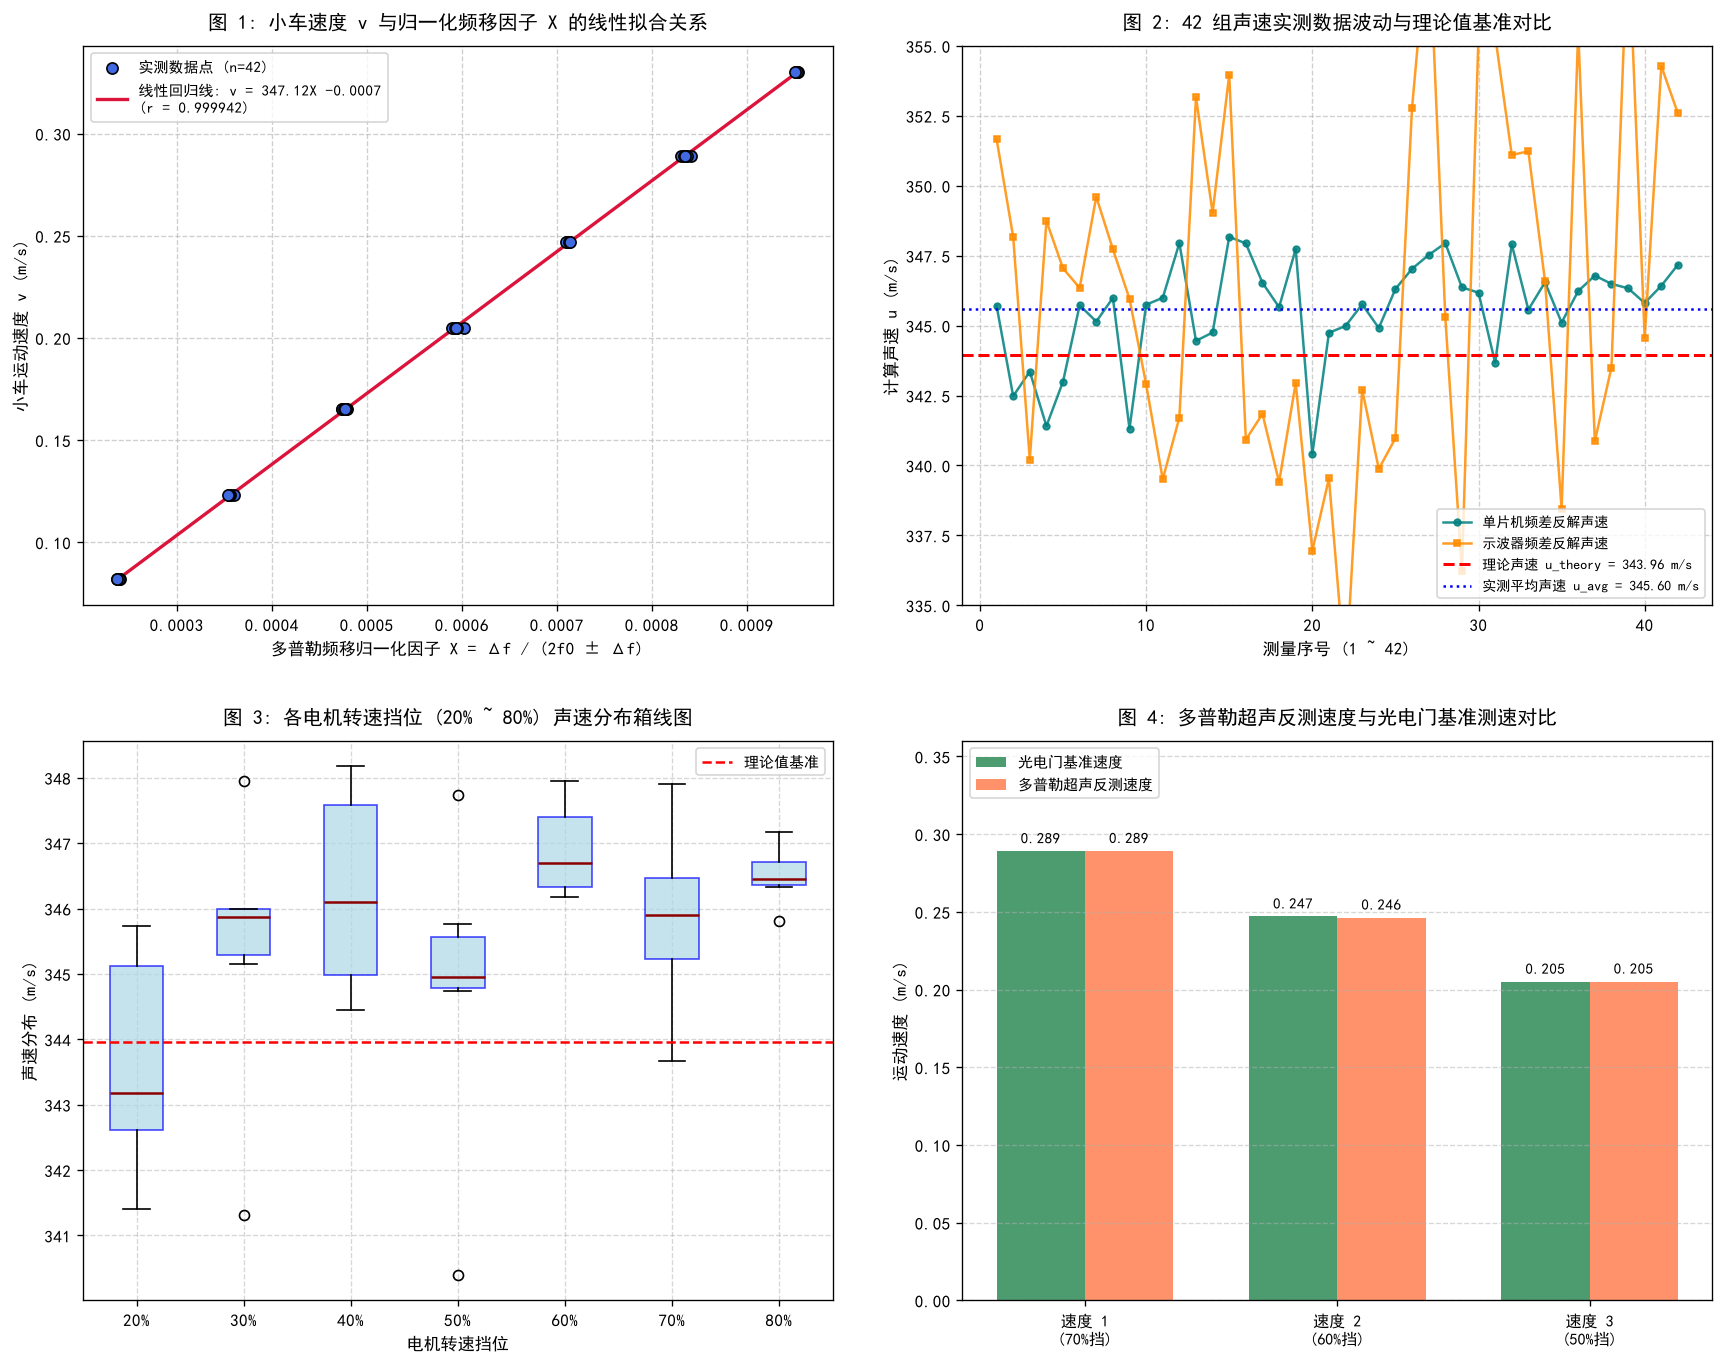

In [48]:
fig = plt.figure(figsize=(15, 12))

# ----------------- 图 1: v - X 最小二乘法拟合曲线 -----------------
ax1 = plt.subplot(2, 2, 1)
x_vals_float = [float(x) for x in X_factor_list]
y_vals_float = [float(y) for y in v_list]
ax1.scatter(x_vals_float, y_vals_float, color='royalblue', edgecolors='k', s=45, label='实测数据点 (n=42)', zorder=3)

x_line = [min(x_vals_float), max(x_vals_float)]
y_line = [float(k_fit) * x + float(b_fit) for x in x_line]
ax1.plot(x_line, y_line, color='crimson', linewidth=2.0, label=f'线性回归线: v = {float(k_fit):.2f}X {float(b_fit):+.4f}\n(r = {float(r_fit):.6f})', zorder=2)

ax1.set_title('图 1: 小车速度 v 与归一化频移因子 X 的线性拟合关系', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('多普勒频移归一化因子 X = Δf / (2f0 ± Δf)', fontsize=10)
ax1.set_ylabel('小车运动速度 v (m/s)', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper left', fontsize=9)

# ----------------- 图 2: 仪器直读声速 vs 示波器测量声速 -----------------
ax2 = plt.subplot(2, 2, 2)
meas_indices = list(range(1, n_samples + 1))
u_inst_float = [float(u) for u in u_inst_list]
u_osc_float = [float(u) for u in u_osc_list]
u_th_val = float(u_theory)

ax2.plot(meas_indices, u_inst_float, marker='o', markersize=4, color='teal', label='单片机频差反解声速', alpha=0.85)
ax2.plot(meas_indices, u_osc_float, marker='s', markersize=4, color='darkorange', label='示波器频差反解声速', alpha=0.85)
ax2.axhline(u_th_val, color='red', linestyle='--', linewidth=1.8, label=f'理论声速 u_theory = {u_th_val:.2f} m/s')
ax2.axhline(float(mean_u_inst), color='blue', linestyle=':', linewidth=1.5, label=f'实测平均声速 u_avg = {float(mean_u_inst):.2f} m/s')

ax2.set_title('图 2: 42 组声速实测数据波动与理论值基准对比', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('测量序号 (1 ~ 42)', fontsize=10)
ax2.set_ylabel('计算声速 u (m/s)', fontsize=10)
ax2.set_ylim([335, 355])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='lower right', fontsize=8.5)

# ----------------- 图 3: 各挡位电机转速下的声速分布箱线图 -----------------
ax3 = plt.subplot(2, 2, 3)
gear_labels = list(exp1_raw_dict.keys())
gear_sound_speeds = []
for gear in gear_labels:
    v = exp1_raw_dict[gear][0]
    dfs = exp1_raw_dict[gear][1]
    speeds = []
    for i, df in enumerate(dfs):
        if i % 2 == 0:
            u_val = float(((Decimal("2") * f0 + df) / df) * v)
        else:
            u_val = float(((Decimal("2") * f0 - df) / df) * v)
        speeds.append(u_val)
    gear_sound_speeds.append(speeds)

try:
    box = ax3.boxplot(gear_sound_speeds, tick_labels=gear_labels, patch_artist=True,
                      boxprops=dict(facecolor='lightblue', color='blue', alpha=0.7),
                      medianprops=dict(color='darkred', linewidth=1.5))
except TypeError:
    box = ax3.boxplot(gear_sound_speeds, labels=gear_labels, patch_artist=True,
                      boxprops=dict(facecolor='lightblue', color='blue', alpha=0.7),
                      medianprops=dict(color='darkred', linewidth=1.5))

ax3.axhline(u_th_val, color='red', linestyle='--', linewidth=1.5, label='理论值基准')
ax3.set_title('图 3: 各电机转速挡位 (20% ~ 80%) 声速分布箱线图', fontsize=12, fontweight='bold', pad=10)
ax3.set_xlabel('电机转速挡位', fontsize=10)
ax3.set_ylabel('声速分布 (m/s)', fontsize=10)
ax3.grid(True, linestyle='--', alpha=0.5)
ax3.legend(loc='upper right', fontsize=9)

# ----------------- 图 4: 实验二多普勒反测速度对比 -----------------
ax4 = plt.subplot(2, 2, 4)
speed_tags = list(exp2_speed_res.keys())
v_bench_vals = [float(exp2_speed_res[s]['v_bench']) for s in speed_tags]
v_calc_vals = [float(exp2_speed_res[s]['avg_v_calc']) for s in speed_tags]

x_pos = [0, 1, 2]
width = 0.35
ax4.bar([p - width/2 for p in x_pos], v_bench_vals, width=width, label='光电门基准速度', color='seagreen', alpha=0.85)
ax4.bar([p + width/2 for p in x_pos], v_calc_vals, width=width, label='多普勒超声反测速度', color='coral', alpha=0.85)

for p, vb, vc in zip(x_pos, v_bench_vals, v_calc_vals):
    ax4.text(p - width/2, vb + 0.005, f'{vb:.3f}', ha='center', fontsize=9)
    ax4.text(p + width/2, vc + 0.005, f'{vc:.3f}', ha='center', fontsize=9)

ax4.set_xticks(x_pos)
ax4.set_xticklabels([f'{s}\n(70%挡)' if s=='速度 1' else f'{s}\n(60%挡)' if s=='速度 2' else f'{s}\n(50%挡)' for s in speed_tags], fontsize=9.5)
ax4.set_title('图 4: 多普勒超声反测速度与光电门基准测速对比', fontsize=12, fontweight='bold', pad=10)
ax4.set_ylabel('运动速度 (m/s)', fontsize=10)
ax4.set_ylim([0, 0.36])
ax4.grid(True, linestyle='--', alpha=0.5, axis='y')
ax4.legend(loc='upper left', fontsize=9)

plt.tight_layout(pad=3.0)
plt.show()


### 6. 实验测量结果规范化汇报与四舍六入五凑偶修约

根据《大学物理实验》教学大纲与国家计量技术规范（JJF 1059）：
1. **修约法则**：严格执行“四舍六入五凑偶（`ROUND_HALF_EVEN`）”；
2. **不确定度保留位数**：绝对不确定度统一保留 1 位有效数字（$u_A = 0.2861\,\mathrm{m/s} \to \mathbf{0.3\,\mathrm{m/s}}$，末位在十分位）；
3. **有效位末位对齐铁律**：测量结果最终主值 $\bar{u}$ 的末位必须与不确定度在相同数量级上严格对齐（$\bar{u} = 345.6012\,\mathrm{m/s} \to \mathbf{345.6\,\mathrm{m/s}}$）；
4. **最终测量结果给出**：
   $$\mathbf{u = (345.6 \pm 0.3)\,\mathrm{m/s}}$$


In [49]:
# 调用 python.utils 中的 scientific_round 进行国家计量规范修约
u_val_final, u_unc_final = scientific_round(mean_u_inst, u_a_inst)
rel_unc_percent = u_a_inst / mean_u_inst * Decimal("100")
err_theory_percent = abs(mean_u_inst - u_theory) / u_theory * Decimal("100")

print("=" * 66)
print("          ★ 反射式多普勒效应综合实验结果总结报告 ★")
print("=" * 66)
print(f"1. 实验环境参数与理论基准:")
print(f"   * 实验室室内温度        : t = {t_celsius:.1f} ℃ ({t_start} ℃ ~ {t_end} ℃)")
print(f"   * 干燥空气理论声速      : u_theory = {float(u_theory):.3f} m/s")
print(f"   * 超声波中心工作频率    : f0 = {float(f0):.1f} Hz (40 kHz)")
print(f"   * 光电门挡光板长度      : d = {float(d_gate)*100:.2f} cm")
print("-" * 66)
print(f"2. 实验一声速测定与不确定度评定 (n = 42 次实测):")
print(f"   * 实测声速平均值        : u_avg = {float(mean_u_inst):.4f} m/s")
print(f"   * 样本实验标准差        : s = {float(s_u_inst):.4f} m/s")
print(f"   * A 类标准不确定度      : u_A = {float(u_a_inst):.4f} m/s")
print(f"   * 规范化测量结果        : u = ({u_val_final} ± {u_unc_final}) m/s")
print(f"   * 相对标准不确定度      : u_r = {float(rel_unc_percent):.2f}%")
print(f"   * 与理论声速相对误差    : E_r = {float(err_theory_percent):.2f}%")
print("-" * 66)
print(f"3. 线性拟合验证多普勒效应:")
print(f"   * 拟合声速斜率          : u_fit = ({float(k_fit):.2f} ± {float(u_k_fit):.2f}) m/s")
print(f"   * 拟合截距 (零点漂移)   : b = {float(b_fit):.6f} m/s")
print(f"   * 线性相关系数          : r = {float(r_fit):.6f} (验证良好线性正比关系)")
print(f"   * 拟合声速相对误差      : E_r(fit) = {float(rel_err_fit):.2f}%")
print("-" * 66)
print(f"4. 实验二超声测速结果 (与光电门基准对比):")
print(f"   * 速度 1 (70% 挡位)     : 基准 {float(exp2_speed_res['速度 1']['v_bench']):.3f} m/s, 反测 {float(exp2_speed_res['速度 1']['avg_v_calc']):.4f} m/s (偏差 {float(exp2_speed_res['速度 1']['avg_rel']):.2f}%)")
print(f"   * 速度 2 (60% 挡位)     : 基准 {float(exp2_speed_res['速度 2']['v_bench']):.3f} m/s, 反测 {float(exp2_speed_res['速度 2']['avg_v_calc']):.4f} m/s (偏差 {float(exp2_speed_res['速度 2']['avg_rel']):.2f}%)")
print(f"   * 速度 3 (50% 挡位)     : 基准 {float(exp2_speed_res['速度 3']['v_bench']):.3f} m/s, 反测 {float(exp2_speed_res['速度 3']['avg_v_calc']):.4f} m/s (偏差 {float(exp2_speed_res['速度 3']['avg_rel']):.2f}%)")
print(f"   * 18 组超声测速总平均偏差: {float(overall_avg_rel):.2f}%")
print("=" * 66)


          ★ 反射式多普勒效应综合实验结果总结报告 ★
1. 实验环境参数与理论基准:
   * 实验室室内温度        : t = 21.0 ℃ (20.8 ℃ ~ 21.2 ℃)
   * 干燥空气理论声速      : u_theory = 343.955 m/s
   * 超声波中心工作频率    : f0 = 40000.0 Hz (40 kHz)
   * 光电门挡光板长度      : d = 5.00 cm
------------------------------------------------------------------
2. 实验一声速测定与不确定度评定 (n = 42 次实测):
   * 实测声速平均值        : u_avg = 345.6012 m/s
   * 样本实验标准差        : s = 1.8543 m/s
   * A 类标准不确定度      : u_A = 0.2861 m/s
   * 规范化测量结果        : u = (345.6 ± 0.3) m/s
   * 相对标准不确定度      : u_r = 0.08%
   * 与理论声速相对误差    : E_r = 0.48%
------------------------------------------------------------------
3. 线性拟合验证多普勒效应:
   * 拟合声速斜率          : u_fit = (347.12 ± 0.59) m/s
   * 拟合截距 (零点漂移)   : b = -0.000732 m/s
   * 线性相关系数          : r = 0.999942 (验证良好线性正比关系)
   * 拟合声速相对误差      : E_r(fit) = 0.92%
------------------------------------------------------------------
4. 实验二超声测速结果 (与光电门基准对比):
   * 速度 1 (70% 挡位)     : 基准 0.289 m/s, 反测 0.2891 m/s (偏差 0.33%)
   * 速度 2 (60% 挡位)     : 基准 0.247 m

---

## 二、思考题研讨与解答

### 【思考题 1】
**该实验中发射与接收换能器位于导轨一端，小车运动反射的回波与发出的 40kHz 信号产生差频（即频移），在实验原理部分已给出相应 $\Delta f$、$v$ 公式。请推导发送换能器在导轨上固定，接收换能器在小车上运动时的 $\Delta f$、$v$ 表达式，并对比两者的物理机制。**

#### 【详细解答与公式推导】
1. **物理模型分析**：
   * 波源（发送换能器）固定在导轨右端静止，在空气介质中以固有频率 $f_0$ 发射超声波，声速为 $u$；
   * 观察者（接收换能器）安装在运动小车上，以速度 $v$ 随小车运动。

2. **小车靠近波源运动（相向运动，速度大小为 $v$）**：
   根据多普勒效应通用公式（讲义公式 2），此时波源静止（$v_2 = 0$），接收端相向运动（$v_1 = v$）：
   $$f_{\text{rx}} = \frac{u + v}{u} f_0$$
   接收端接收到的频率高于发射频率，多普勒频差 $\Delta f$ 为：
   $$\Delta f = f_{\text{rx}} - f_0 = \frac{u + v}{u} f_0 - f_0 = \frac{v}{u} f_0$$
   反解小车运动速度 $v$ 与声速 $u$：
   $$v = \frac{\Delta f}{f_0} u, \qquad u = \frac{f_0}{\Delta f} v$$

3. **小车远离波源运动（背向运动，速度大小为 $v$）**：
   接收端背离波源运动（$v_1 = -v$）：
   $$f_{\text{rx}} = \frac{u - v}{u} f_0$$
   多普勒频差为：
   $$\Delta f = f_0 - f_{\text{rx}} = \frac{v}{u} f_0$$
   反解表达式与靠近时完全一致：
   $$v = \frac{\Delta f}{f_0} u, \qquad u = \frac{f_0}{\Delta f} v$$

4. **物理机制对比**：
   * **单程模式（接收换能器在小车上运动）**：声波仅发生**一次多普勒频移**，频差严格满足 $\Delta f = \frac{v}{u} f_0$。靠近与远离的频差表达式完全对称，且与运动方向标量无关；
   * **双程反射模式（本实验采用模式）**：声波经历了“小车接收”与“小车反射发射”**两次多普勒频移**。靠近时 $\Delta f = \frac{2v}{u - v} f_0$，远离时 $\Delta f = \frac{2v}{u + v} f_0$。在低速下频差近似为单程模式的 **2 倍**（$\Delta f \approx \frac{2v}{u} f_0$），极大提高了实验仪器的频移灵敏度和信噪比。

---

### 【思考题 2】
**分析该实验中误差的主要来源。**

#### 【详细解答】
根据讲义原理与实验过程，本实验误差主要来源包括：
1. **环境温度波动与空间温度梯度**：
   * 空气声速强烈依赖温度（$u = 331.45\sqrt{1 + t/273.15}$，每变化 $1\,^\circ\mathrm{C}$ 声速漂移约 $0.6\,\mathrm{m/s}$）；实验过程中室内温度由 $20.8\,^\circ\mathrm{C}$ 升至 $21.2\,^\circ\mathrm{C}$，且导轨沿线空气对流与散热不均会引入系统偏差；
2. **发射换能器工作频率偏离共振峰**：
   * 压电陶瓷发射头的最佳谐振中心频率为 $40.0\,\mathrm{kHz}$，若信号源频率发生晶振漂移，或小车反射回波强度衰减，会导致混频电路差频信号失真；
3. **小车运动速度的均匀度与光电门测量误差**：
   * 导轨若未严格水平，小车在运行中受微弱重力分量或摩擦力影响并非严格匀速运动；
   * 光电门测得的是小车挡光片（宽度 $5.00\,\mathrm{cm}$）通过光电门时的平均速度，与小车反射超声波时的瞬时速度存在微小的时间与空间偏差；
4. **超声波束传播方向与导轨轴线的微小倾角**：
   * 发射探头、小车反射板与接收探头的几何连线若未严格平行于导轨连线，存在微小夹角 $\alpha$ 时，实际多普勒频移取决于 $v \cos\alpha$，导致计算声速略有偏高。
